# Read a warming window without inventing an observation

**Learning question:** How do latitude weighting and missing coverage change the mean of a small synthetic climate field?

Twenty complete source lessons connect anomalies, regions and uncertainty with a real model-window table, real generalized coastline, catalogue metadata and separately labelled synthetic arrays.

This introductory calculation is an original **synthetic** teaching exercise. Full source lessons and their actual data status are separately described below.


## Predict before running

Equal-angle grid cells cover less area toward the poles. For this two-band thought experiment, use cosine(latitude) as a relative area weight and exclude missing values from both numerator and denominator. A warming-level window is a model/scenario time interval, not a measured temperature or a prediction for one city.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Latitude bands: [0, 60] synthetic field: [[0, 0], [9, 9]]
Valid cells: full 4; missing example 3. Missing is not zero.
Synthetic latitude weighting and coverage | degrees C: {'unweighted': 4.5, 'area weighted': 3.0, 'one cell missing': 4.5}


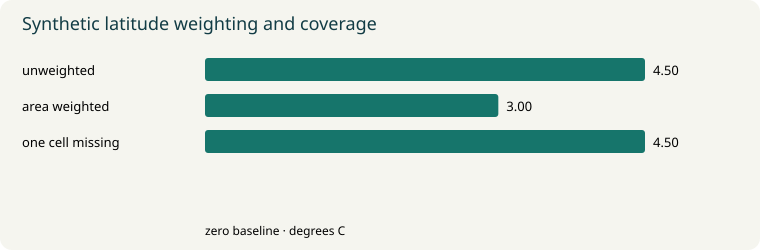

In [2]:
from math import cos, radians
latitudes = [0, 60]
field = [[0, 0], [9, 9]]  # synthetic temperature changes, degrees C
def area_mean(values):
    pairs = [(value, cos(radians(lat))) for lat,row in zip(latitudes,values) for value in row if value is not None]
    if not pairs:
        raise ValueError('No valid area remains')
    return sum(value*weight for value,weight in pairs)/sum(weight for _,weight in pairs)
full_mean = area_mean(field)
missing_mean = area_mean([[0, None], [9, 9]])
print('Latitude bands:', latitudes, 'synthetic field:', field)
print('Valid cells: full 4; missing example 3. Missing is not zero.')
bars({'unweighted':4.5,'area weighted':full_mean,'one cell missing':missing_mean}, 'Synthetic latitude weighting and coverage', 'degrees C')


## Interpret the result

The complete area-weighted mean is 3 degrees C; with one equatorial zero missing it is 4.5. The unweighted complete mean is also 4.5 for a different reason. Equal answers do not establish equivalent support. Cosine weighting here assumes equal longitude widths and representative band centres; real cell bounds and masks require their own weights.

## Change one thing

Replace the missing cell with zero, then move the second latitude to 30 degrees. Predict the direction before rerunning. In source lesson 12 inspect the actual CMIP6 model/scenario/threshold window and distinguish its endpoints from its midpoint. In lesson 14 compare complete and masked coverage before reporting a mean.


## Source course and scientific boundaries

All 20 source notebooks, atlas_helpers.py, data manifest, licenses, credits, data guide and learning resources are bundled in the course. Browser setup prepares numpy, pandas, matplotlib and Plotly 6.5.0. Local figures and numerical alternatives remain available; optional interactive Plotly rendering needs its versioned CDN/WebGL. Authenticated CDS downloads, xarray/netCDF4 preparation, archives and native regridding remain source/desktop continuations.

[Complete local course guide](../../courses/c3s-atlas/index.ipynb) · [Notebook library](../../notebook-library.ipynb)


## Sources, attribution and limits

[Reviewed source README](https://github.com/jltobias/JupyterLite-C3S-Atlas/blob/b41c3e1098a4fb94cef48b3044fe19c6ce7c1a1a/README.md) · [Source repository](https://github.com/jltobias/JupyterLite-C3S-Atlas)

Original course MIT. Retain European Union/C3S/ECMWF, CSIC/Predictia and underlying CMIP6 modelling-group credit. The real warming-level auxiliary CSV is Apache-2.0, the Natural Earth coastline is public domain, and the CC BY 4.0 CDS catalogue snapshot is metadata rather than gridded climate data. monthly_series.csv and generated lesson arrays are explicitly synthetic (seed 381). The cleared original splash and its generation provenance are retained. References include Gutiérrez et al. (2024), DOI 10.21957/ah52ufc369; Iturbide et al. (2020), DOI 10.5194/essd-12-2959-2020; CDS dataset DOI 10.24381/cds.h35hb680.

- [Read source Book](https://jltobias.github.io/JupyterLite-C3S-Atlas/book/index.html) — Source-route reviewed; HTTP entry not freshly checked
- [Run source Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=01-atlas-orientation.ipynb) — Source-route reviewed; HTTP entry not freshly checked
- [Open source portal](https://jltobias.github.io/JupyterLite-C3S-Atlas/) — Source-route reviewed; HTTP entry not freshly checked
- [Explore C3S teaching maps](https://jltobias.github.io/JupyterLite-C3S-Atlas/maps/) — Source-route reviewed; HTTP entry not freshly checked
- [Explore C3S teaching globe](https://jltobias.github.io/JupyterLite-C3S-Atlas/globe/) — Source-route reviewed; HTTP entry not freshly checked
- [Explore C3S teaching scenes](https://jltobias.github.io/JupyterLite-C3S-Atlas/scenes/) — Source-route reviewed; HTTP entry not freshly checked

[Central references](../../references.ipynb)


## Browser GIS pathway

**Geographic question:** How does a real coastline context differ from a synthetic climate field and a model warming window?

**Data readiness (B + O):** The bundled Natural Earth coastline is real generalized geography. The C3S warming-level CSV has model/scenario windows; the CDS snapshot is catalogue metadata. Seeded monthly values are synthetic and have no point geometry.

**Start from the chapter evidence:** [warming windows](../../courses/c3s-atlas/12-global-warming-levels.ipynb) · [region weights](../../courses/c3s-atlas/14-regions-and-weights.ipynb) · [Natural Earth coastline](https://github.com/jltobias/JupyterLite-Learning-Atlas/blob/main/content/courses/c3s-atlas/data/reference/ne_110m_coastline.geojson) (`courses/c3s-atlas/data/reference/ne_110m_coastline.geojson`) · [source manifest](https://github.com/jltobias/JupyterLite-Learning-Atlas/blob/main/content/courses/c3s-atlas/data/manifest.json) (`courses/c3s-atlas/data/manifest.json`)

- **[RustGIS Web](https://web.rustgis.app/):** Inspect a bounded copy of the attributed coastline and its CRS before import. Keep synthetic climate values separate; do not turn model-window rows into measured local temperatures.
- **[GeoLibre Web](https://web.geolibre.app/):** Compare the same coastline extent and one feature identifier with RustGIS. Use a separate synthetic geographic layer only after explicitly defining its support, units and fixture status.

**Handoff:** Use the [GIS workbench](../../gis-workbench.ipynb) to validate/export an attributed WGS84 layer. Download the GeoJSON, method record and review prompt from `exports/`, then import through the chosen app’s file picker. Compare `_atlas_source_id` (or source `GEOID`) with the original IDs; app-generated internal IDs may differ. Return changed results by explicit upload. Apps and the notebook share no files or kernel state. Practice-only Census data remain Fresno 2020, never this subject’s observations.

**Optional AI prompt (approved subject evidence only):** “Explain why the supplied model/scenario window and synthetic monthly series cannot establish a local observed trend. Cite supplied feature IDs/fields, separate observations from assumptions, abstain when evidence is missing, and propose one falsifiable check.” For the common practice package, use its generated schema/summary prompt instead. A human-written answer completes the same task.

**GeoAI opportunity:** A later regional emulator needs independent held-out model/time windows and a stated target; latitude weights and map styling are deterministic analysis. Any later fitted exercise must name target/features and spatial/temporal support, reserve a spatial/temporal holdout, inspect leakage and uncertainty, and state evidence that would disprove the interpretation. Styling, thresholds, schema checks and chat alone are not model fitting.

**Human evidence check:** Retain Natural Earth credit, model/scenario/threshold/endpoints, synthetic labels and valid-area denominator. Ask the intended reader which decision the map supports; change one legend, filter or annotation, then recheck interpretation against the same IDs and values.

**Continue:** [cross-tool guide and optional Ollama setup](../../browser-gis.ipynb) · [RustGIS assistance](../../courses/rustgis/07_ollama_assistance.ipynb) · [GeoLibre setup](../../courses/geolibre-geoai/18_ollama_geolibre_setup.ipynb) · [chat-to-map](../../courses/geolibre-geoai/19_ollama_chat_to_map.ipynb) · [evidence review](../../courses/geolibre-geoai/20_ollama_evidence_review.ipynb). AI is optional; no service or model is called by this pathway.
